# Spacetime Sentinel — Reproducible Analysis Notebook

This notebook reuses the project’s `engine.py` (and optionally its T-doping methods) rather than reimplementing the simulator. Defaults reproduce **Level 1 with seed 67**. It builds the session, prints the no-check and reference results, then evaluates every available ordered check-target selection up to the level's ancilla budget.

This is an exhaustive small-level analysis and can become expensive at higher levels. Results are saved as CSV files in `analysis_results/`.

In [1]:
# ======================= USER CONFIGURATION =======================

LEVEL_NUMBER = 1                   # 1..len(engine.LEVELS); default is Level 1, goes up to Level 5 in the current engine.py
SEED = 67                          # all engine seeds derive reproducibly from this value

# None means use the project's current engine.py defaults.
STABILIZER_SAMPLES = None          # engine.N_STABS; for example 10
SHOTS_PER_STABILIZER = None        # engine.SHOTS_PER_STAB; for example 2000
RAW_SHOTS_FOR_SCORE = None         # engine.S_SHOTS; default 1000
GATE_NOISE_SCALE_OVERRIDE = None   # None = use engine default; for example 1.0
BACKEND_CANDIDATES_OVERRIDE = None # None = use engine default; e.g. ["FakeFez"]

MAX_CHECKS_OVERRIDE = None         # None = use this level's full check/ancilla budget
SWEEP_ORDERED_TARGETS = True       # True = every ordering (recommended; order can matter)
MAX_TARGET_ORDERS = None           # None = all orders; use e.g. 10 for a quick pilot
LARGE_SWEEP_THRESHOLD = 150        # guardrail for larger levels
CONFIRM_LARGE_SWEEP = False        # set True to explicitly allow a sweep above the threshold

RUN_T_DOPING_SWEEP = True          # optional: run T counts [0, 1, 2, 4, 8] on the best checked case
SAVE_CSV = False
OUTPUT_DIR = "analysis_results"


In [2]:
# ======================= IMPORTS AND REPRODUCIBLE SETUP =======================
from pathlib import Path
from itertools import permutations, combinations
from time import perf_counter
import math
import numpy as np
import pandas as pd
from IPython.display import display
import engine

# Set engine-level parameters before constructing LevelSession.
if STABILIZER_SAMPLES is not None:
    if int(STABILIZER_SAMPLES) < 1:
        raise ValueError("STABILIZER_SAMPLES must be >= 1")
    engine.N_STABS = int(STABILIZER_SAMPLES)
if SHOTS_PER_STABILIZER is not None:
    if int(SHOTS_PER_STABILIZER) < 1:
        raise ValueError("SHOTS_PER_STABILIZER must be >= 1")
    engine.SHOTS_PER_STAB = int(SHOTS_PER_STABILIZER)
if RAW_SHOTS_FOR_SCORE is not None:
    if int(RAW_SHOTS_FOR_SCORE) < 1:
        raise ValueError("RAW_SHOTS_FOR_SCORE must be >= 1")
    engine.S_SHOTS = int(RAW_SHOTS_FOR_SCORE)
if GATE_NOISE_SCALE_OVERRIDE is not None:
    if float(GATE_NOISE_SCALE_OVERRIDE) < 0:
        raise ValueError("GATE_NOISE_SCALE_OVERRIDE must be >= 0")
    engine.GATE_NOISE_SCALE = float(GATE_NOISE_SCALE_OVERRIDE)
if BACKEND_CANDIDATES_OVERRIDE is not None:
    if not BACKEND_CANDIDATES_OVERRIDE:
        raise ValueError("BACKEND_CANDIDATES_OVERRIDE must be None or a non-empty list")
    engine.BACKEND_CANDIDATES = list(BACKEND_CANDIDATES_OVERRIDE)
    engine._BACKEND = None  # force selection from the requested candidate list

if not (1 <= int(LEVEL_NUMBER) <= len(engine.LEVELS)):
    raise ValueError(f"LEVEL_NUMBER must be between 1 and {len(engine.LEVELS)}")

level_index = int(LEVEL_NUMBER) - 1
level = engine.LEVELS[level_index]
print(f"Creating {level.name} with seed={SEED} ...")
setup_started = perf_counter()
session = engine.LevelSession(level_index, int(SEED))
setup_seconds = perf_counter() - setup_started

metadata = pd.DataFrame([{
    "Level": level.name,
    "Level index": level_index,
    "Seed": int(SEED),
    "Width (data qubits)": session.level.width,
    "Payload depth setting (CZ layers)": session.level.depth,
    "Available check targets": str(session.allowed),
    "Ancilla/check budget": session.budget,
    "Backend": session.backend.name,
    "Physical layout": str(session.layout),
    "Gate-noise parameter": session.gn,
    "Readout-noise parameter": session.ro,
    "Stabilizers sampled": len(session.stabs),
    "Shots per stabilizer": engine.SHOTS_PER_STAB,
    "Raw shots in score objective": engine.S_SHOTS,
    "Setup seconds": round(setup_seconds, 2),
}])
display(metadata)


Creating 1. First light with seed=67 ...


,Level,Level index,Seed,Width (data qubits),Payload depth setting (CZ layers),Available check targets,Ancilla/check budget,Backend,Physical layout,Gate-noise parameter,Readout-noise parameter,Stabilizers sampled,Shots per stabilizer,Raw shots in score objective,Setup seconds
0,1. First light,0,67,3,10,"[0, 1, 2]",2,fake_fez,"[22, 23, 24]",0.002581,0.006917,7,2000,1000,11.48


In [3]:
# ======================= ENUMERATE ALL CHECK-TARGET ORDERS =======================
available_targets = list(session.allowed)
max_checks = session.budget
if MAX_CHECKS_OVERRIDE is not None:
    if int(MAX_CHECKS_OVERRIDE) < 0:
        raise ValueError("MAX_CHECKS_OVERRIDE must be >= 0 or None")
    max_checks = min(max_checks, int(MAX_CHECKS_OVERRIDE))

selector = permutations if SWEEP_ORDERED_TARGETS else combinations
target_orders = []
for number_of_checks in range(1, min(max_checks, len(available_targets)) + 1):
    target_orders.extend(tuple(x) for x in selector(available_targets, number_of_checks))
if MAX_TARGET_ORDERS is not None:
    if int(MAX_TARGET_ORDERS) < 1:
        raise ValueError("MAX_TARGET_ORDERS must be >= 1 or None")
    target_orders = target_orders[:int(MAX_TARGET_ORDERS)]

print(f"Available target sites: {available_targets}")
print(f"Max checks in this sweep: {max_checks}")
print(f"Target orders to evaluate: {len(target_orders)}")
print("Selection mode:", "all ordered permutations" if SWEEP_ORDERED_TARGETS else "combinations in ascending site order")
if len(target_orders) > LARGE_SWEEP_THRESHOLD and not CONFIRM_LARGE_SWEEP:
    raise RuntimeError(
        f"This setting creates {len(target_orders)} target orders, above LARGE_SWEEP_THRESHOLD="
        f"{LARGE_SWEEP_THRESHOLD}. For an exhaustive run, set CONFIRM_LARGE_SWEEP=True; "
        "for a pilot, set MAX_TARGET_ORDERS to a smaller number."
    )
if not target_orders:
    raise RuntimeError("No target orders to evaluate. Check MAX_CHECKS_OVERRIDE and the available check sites.")


Available target sites: [0, 1, 2]
Max checks in this sweep: 2
Target orders to evaluate: 9
Selection mode: all ordered permutations


In [4]:
# ======================= RUN THE EXHAUSTIVE CHECK SWEEP =======================
# We call the same cached _objs/_evaluate machinery as LevelSession.run(), but do not
# consume the game's limited interactive-run allowance or append analysis trials to history.

def score_and_stars(error_value):
    score = (100.0 * session.par["error"] / error_value) if error_value > 0 else float("inf")
    return score, session.stars({"score": score})

analysis_records = []
visualization_records = []  # keep representative circuits and fault-location cells for game-style plots
start_sweep = perf_counter()
progress_every = max(1, len(target_orders) // 10)
for selection_index, requested_order in enumerate(target_orders, start=1):
    objects_by_stabilizer = session._objs(list(requested_order))
    kmax = min(len(objects) - 1 for objects in objects_by_stabilizer)
    variant_results = session._evaluate(objects_by_stabilizer, kmax)

    # Match the engine's own interpretation of successful target order.
    final_obj = objects_by_stabilizer[0][-1]
    actual_order = list(getattr(final_obj, "target_qubits", ())) or list(requested_order)

    for variant in variant_results:
        checks_inserted = int(variant["k"])
        if checks_inserted == 0:
            # The unique no-check case is reported in the reference table below.
            continue
        actual_targets = tuple(actual_order[:checks_inserted])
        score, stars = score_and_stars(float(variant["error"]))
        record = {
            "Configuration": "Checked selection",
            "Configuration type": "With checks",
            "Selection index": selection_index,
            "Requested target order": tuple(requested_order),
            "Actual check targets": actual_targets,
            "Checks inserted": checks_inserted,
            "Fidelity": float(variant["F"]),
            "Fidelity standard error across stabilizers": float(variant["F_err"]),
            "Kept shots (%)": 100.0 * float(variant["K"]),
            "Shots lost (%)": 100.0 * (1.0 - float(variant["K"])),
            "Mean 2Q gates across stabilizer circuits": float(variant["twoq"]),
            "Representative circuit depth": int(variant["depth"]),
            "Ancillas inserted": int(variant["ancillas"]),
            "Remaining undetected fault types (sum)": float(variant["unc_total"]),
            "Trade-off error (lower is better)": float(variant["error"]),
            "Score vs reference": float(score),
            "Stars": int(stars),
            "_actual_targets_tuple": actual_targets,
        }
        for q, value in variant["unc_by_qubit"].items():
            record[f"Remaining exposure q{q}"] = float(value)
        analysis_records.append(record)

        # Preserve the same representative first-stabilizer circuit and fault cells used by the game UI.
        representative_checked = engine.get_circuit(objects_by_stabilizer[0][checks_inserted])
        _, representative_unc_cells = engine.coverage_info(
            objects_by_stabilizer[0][checks_inserted], session.level.width
        )
        visualization_records.append({
            "selection_index": int(selection_index),
            "requested_order": tuple(requested_order),
            "actual_targets": actual_targets,
            "checks_inserted": checks_inserted,
            "F": float(variant["F"]),
            "K": float(variant["K"]),
            "error": float(variant["error"]),
            "twoq": float(variant["twoq"]),
            "depth": int(variant["depth"]),
            "ancillas": int(variant["ancillas"]),
            "unc_by_qubit": dict(variant["unc_by_qubit"]),
            "unc_cells": list(representative_unc_cells),
            "n_inst": len(representative_checked.data),
            "circuit": representative_checked,
        })

    if selection_index % progress_every == 0 or selection_index == len(target_orders):
        elapsed = perf_counter() - start_sweep
        print(f"Finished {selection_index}/{len(target_orders)} target orders; elapsed {elapsed:.1f}s")

sweep_seconds = perf_counter() - start_sweep
results = pd.DataFrame(analysis_records)
if results.empty:
    raise RuntimeError("No successful checked configurations were returned by qiskit-paulice.")
results = results.sort_values(
    ["Trade-off error (lower is better)", "Checks inserted", "Requested target order"],
    kind="stable"
).reset_index(drop=True)
print(f"Completed {len(target_orders)} target orders and recorded {len(results)} checked variants in {sweep_seconds:.1f}s.")


Finished 1/9 target orders; elapsed 5.1s
Finished 2/9 target orders; elapsed 10.2s
Finished 3/9 target orders; elapsed 15.1s
Finished 4/9 target orders; elapsed 23.0s
Finished 5/9 target orders; elapsed 31.0s
Finished 6/9 target orders; elapsed 39.1s
Finished 7/9 target orders; elapsed 47.4s
Finished 8/9 target orders; elapsed 55.3s
Finished 9/9 target orders; elapsed 63.3s
Completed 9 target orders and recorded 15 checked variants in 63.3s.


In [5]:
# ======================= PRINT THE ANALYSIS TABLES =======================
def summarize_reference(name, result):
    score, stars = score_and_stars(float(result["error"]))
    used_targets = tuple(result.get("targets", []))
    row = {
        "Configuration": name,
        "Configuration type": "No checks" if int(result["k"]) == 0 else "Reference checks",
        "Selection index": None,
        "Requested target order": used_targets,
        "Actual check targets": used_targets,
        "Checks inserted": int(result["k"]),
        "Fidelity": float(result["F"]),
        "Fidelity standard error across stabilizers": float(result.get("F_err", 0.0)),
        "Kept shots (%)": 100 * float(result["K"]),
        "Shots lost (%)": 100 * (1 - float(result["K"])),
        "Mean 2Q gates across stabilizer circuits": float(result["twoq"]),
        "Representative circuit depth": int(result["depth"]),
        "Ancillas inserted": int(result["ancillas"]),
        "Remaining undetected fault types (sum)": float(result["unc_total"]),
        "Trade-off error (lower is better)": float(result["error"]),
        "Score vs reference": float(score),
        "Stars": int(stars),
        "_actual_targets_tuple": used_targets,
    }
    for q, value in result["unc_by_qubit"].items():
        row[f"Remaining exposure q{q}"] = float(value)
    return row

reference_records = [
    summarize_reference("No-check baseline", session.baseline),
    summarize_reference("Game reference (score 100)", session.par),
]
reference_table = pd.DataFrame(reference_records)
reference_visible = [c for c in reference_table.columns if not c.startswith("_")]
print("No-check baseline and the game's reference configuration")
display(reference_table[reference_visible].round(5))

# Full checked-configuration table: each returned check-count variant is a separate row.
visible_columns = [c for c in results.columns if not c.startswith("_")]
print("All checked configurations, sorted by the fidelity/shot-retention objective")
display(results[visible_columns].round(5))

print("Summary by number of checks")
by_checks = results.groupby("Checks inserted", as_index=False).agg(
    Configurations=("Trade-off error (lower is better)", "size"),
    Mean_fidelity=("Fidelity", "mean"),
    Best_fidelity=("Fidelity", "max"),
    Mean_kept_shots_percent=("Kept shots (%)", "mean"),
    Best_tradeoff_error=("Trade-off error (lower is better)", "min"),
    Mean_2Q_gates=("Mean 2Q gates across stabilizer circuits", "mean"),
    Mean_depth=("Representative circuit depth", "mean"),
).rename(columns={
    "Mean_fidelity": "Mean fidelity",
    "Best_fidelity": "Best fidelity",
    "Mean_kept_shots_percent": "Mean kept shots (%)",
    "Best_tradeoff_error": "Best trade-off error",
    "Mean_2Q_gates": "Mean 2Q gates",
    "Mean_depth": "Mean depth",
})
display(by_checks.round(5))

print("Summary by realized checked-circuit depth")
by_depth = results.groupby("Representative circuit depth", as_index=False).agg(
    Configurations=("Trade-off error (lower is better)", "size"),
    Mean_fidelity=("Fidelity", "mean"),
    Mean_kept_shots_percent=("Kept shots (%)", "mean"),
    Best_tradeoff_error=("Trade-off error (lower is better)", "min"),
).rename(columns={
    "Mean_fidelity": "Mean fidelity",
    "Mean_kept_shots_percent": "Mean kept shots (%)",
    "Best_tradeoff_error": "Best trade-off error",
})
display(by_depth.round(5))

print("Comparison by requested target placement/order")
by_placement = results[[
    "Requested target order", "Actual check targets", "Checks inserted", "Fidelity",
    "Kept shots (%)", "Trade-off error (lower is better)", "Score vs reference",
    "Stars", "Mean 2Q gates across stabilizer circuits", "Representative circuit depth",
]].sort_values("Trade-off error (lower is better)", kind="stable")
display(by_placement.round(5))

# Include no-check and reference rows in the overall winner ranking.
all_comparison = pd.concat([reference_table, results], ignore_index=True, sort=False)
all_comparison = all_comparison.sort_values("Trade-off error (lower is better)", kind="stable").reset_index(drop=True)
all_visible_columns = [c for c in all_comparison.columns if not c.startswith("_")]
print("Overall ranking (includes no-check and game-reference configurations)")
display(all_comparison[all_visible_columns].round(5))
best_overall = all_comparison.iloc[0]
print(f"Best overall: {best_overall['Configuration']} — objective="
      f"{best_overall['Trade-off error (lower is better)']:.6f}, fidelity={best_overall['Fidelity']:.4f}, "
      f"kept shots={best_overall['Kept shots (%)']:.2f}%.")

# Keep a separate best checked case for the optional T sweep.
best_checked = results.iloc[0]
best_targets = list(best_checked["_actual_targets_tuple"])
print("Best checked configuration")
display(results.iloc[[0]][visible_columns].round(5))
print(f"Best checked targets: {best_targets}; objective="
      f"{best_checked['Trade-off error (lower is better)']:.6f}; "
      f"fidelity={best_checked['Fidelity']:.4f}; kept shots={best_checked['Kept shots (%)']:.2f}%.")

# Exposure table for the best overall option (may be no-check or checked).
exposure_columns = [c for c in all_comparison.columns if c.startswith("Remaining exposure q")]
exposure_table = pd.DataFrame({
    "Qubit": [c.replace("Remaining exposure ", "") for c in exposure_columns],
    "Average undetected fault types": [best_overall[c] for c in exposure_columns],
})
print("Remaining fault exposure for the best overall configuration")
display(exposure_table.round(3))


No-check baseline and the game's reference configuration


,Configuration,Configuration type,Selection index,Requested target order,Actual check targets,Checks inserted,Fidelity,Fidelity standard error across stabilizers,Kept shots (%),Shots lost (%),Mean 2Q gates across stabilizer circuits,Representative circuit depth,Ancillas inserted,Remaining undetected fault types (sum),Trade-off error (lower is better),Score vs reference,Stars,Remaining exposure q0,Remaining exposure q1,Remaining exposure q2
0,No-check baseline,No checks,None,(),(),0,0.93514,0.00377,100.00000,0.00000,10.00000,31,0,69.00000,0.09648,46.75766,0,18.0,33.00000,18.0
1,Game reference (score 100),Reference checks,None,"(0, 1)","(0, 1)",2,0.98748,0.00389,94.16429,5.83571,15.71429,44,2,29.71429,0.04511,100.00000,3,10.0,11.71429,8.0


All checked configurations, sorted by the fidelity/shot-retention objective


,Configuration,Configuration type,Selection index,Requested target order,Actual check targets,Checks inserted,Fidelity,Fidelity standard error across stabilizers,Kept shots (%),Shots lost (%),Mean 2Q gates across stabilizer circuits,Representative circuit depth,Ancillas inserted,Remaining undetected fault types (sum),Trade-off error (lower is better),Score vs reference,Stars,Remaining exposure q0,Remaining exposure q1,Remaining exposure q2
0,Checked selection,With checks,4,"(0, 1)","(0, 1)",2,0.98748,0.00389,94.16429,5.83571,15.71429,44,2,29.71429,0.04511,100.00000,3,10.00000,11.71429,8.00000
1,Checked selection,With checks,9,"(2, 1)","(2, 1)",2,0.98182,0.00464,94.91429,5.08571,14.71429,45,2,28.42857,0.05064,89.08113,1,8.57143,11.00000,8.85714
2,Checked selection,With checks,8,"(2, 0)","(2, 0)",2,0.98185,0.00494,94.67143,5.32857,15.71429,39,2,36.57143,0.05065,89.07267,1,10.28571,13.57143,12.71429
3,Checked selection,With checks,5,"(0, 2)","(0, 2)",2,0.98095,0.00432,94.88571,5.11429,16.00000,40,2,37.57143,0.05151,87.57948,1,13.57143,14.42857,9.57143
4,Checked selection,With checks,6,"(1, 0)","(1, 0)",2,0.97605,0.00385,95.22143,4.77857,15.42857,43,2,32.14286,0.05635,80.05114,1,11.00000,13.00000,8.14286
5,Checked selection,With checks,7,"(1, 2)","(1, 2)",2,0.97131,0.00653,95.15000,4.85000,15.42857,42,2,31.85714,0.06111,73.82360,1,9.42857,12.71429,9.71429
6,Checked selection,With checks,1,"(0,)","(0,)",1,0.95814,0.00515,96.05714,3.94286,13.00000,37,1,44.57143,0.07412,60.85930,1,14.71429,19.28571,10.57143
7,Checked selection,With checks,4,"(0, 1)","(0,)",1,0.95814,0.00515,96.05714,3.94286,13.00000,37,1,44.57143,0.07412,60.85930,1,14.71429,19.28571,10.57143
8,Checked selection,With checks,5,"(0, 2)","(0,)",1,0.95814,0.00515,96.05714,3.94286,13.00000,37,1,44.57143,0.07412,60.85930,1,14.71429,19.28571,10.57143
9,Checked selection,With checks,2,"(1,)","(1,)",1,0.95665,0.00581,96.60714,3.39286,12.14286,40,1,40.85714,0.07552,59.73485,1,11.14286,19.14286,10.57143


Summary by number of checks


...

,Configuration,Configuration type,Selection index,Requested target order,Actual check targets,Checks inserted,Fidelity,Fidelity standard error across stabilizers,Kept shots (%),Shots lost (%),Mean 2Q gates across stabilizer circuits,Representative circuit depth,Ancillas inserted,Remaining undetected fault types (sum),Trade-off error (lower is better),Score vs reference,Stars,Remaining exposure q0,Remaining exposure q1,Remaining exposure q2
0,Game reference (score 100),Reference checks,None,"(0, 1)","(0, 1)",2,0.98748,0.00389,94.16429,5.83571,15.71429,44,2,29.71429,0.04511,100.00000,3,10.00000,11.71429,8.00000
1,Checked selection,With checks,4,"(0, 1)","(0, 1)",2,0.98748,0.00389,94.16429,5.83571,15.71429,44,2,29.71429,0.04511,100.00000,3,10.00000,11.71429,8.00000
2,Checked selection,With checks,9,"(2, 1)","(2, 1)",2,0.98182,0.00464,94.91429,5.08571,14.71429,45,2,28.42857,0.05064,89.08113,1,8.57143,11.00000,8.85714
3,Checked selection,With checks,8,"(2, 0)","(2, 0)",2,0.98185,0.00494,94.67143,5.32857,15.71429,39,2,36.57143,0.05065,89.07267,1,10.28571,13.57143,12.71429
4,Checked selection,With checks,5,"(0, 2)","(0, 2)",2,0.98095,0.00432,94.88571,5.11429,16.00000,40,2,37.57143,0.05151,87.57948,1,13.57143,14.42857,9.57143
5,Checked selection,With checks,6,"(1, 0)","(1, 0)",2,0.97605,0.00385,95.22143,4.77857,15.42857,43,2,32.14286,0.05635,80.05114,1,11.00000,13.00000,8.14286
6,Checked selection,With checks,7,"(1, 2)","(1, 2)",2,0.97131,0.00653,95.15000,4.85000,15.42857,42,2,31.85714,0.06111,73.82360,1,9.42857,12.71429,9.71429
7,Checked selection,With checks,1,"(0,)","(0,)",1,0.95814,0.00515,96.05714,3.94286,13.00000,37,1,44.57143,0.07412,60.85930,1,14.71429,19.28571,10.57143
8,Checked selection,With checks,4,"(0, 1)","(0,)",1,0.95814,0.00515,96.05714,3.94286,13.00000,37,1,44.57143,0.07412,60.85930,1,14.71429,19.28571,10.57143
9,Checked selection,With checks,5,"(0, 2)","(0,)",1,0.95814,0.00515,96.05714,3.94286,13.00000,37,1,44.57143,0.07412,60.85930,1,14.71429,19.28571,10.57143


Best overall: Game reference (score 100) — objective=0.045112, fidelity=0.9875, kept shots=94.16%.
Best checked configuration


,Configuration,Configuration type,Selection index,Requested target order,Actual check targets,Checks inserted,Fidelity,Fidelity standard error across stabilizers,Kept shots (%),Shots lost (%),Mean 2Q gates across stabilizer circuits,Representative circuit depth,Ancillas inserted,Remaining undetected fault types (sum),Trade-off error (lower is better),Score vs reference,Stars,Remaining exposure q0,Remaining exposure q1,Remaining exposure q2
0,Checked selection,With checks,4,"(0, 1)","(0, 1)",2,0.98748,0.00389,94.16429,5.83571,15.71429,44,2,29.71429,0.04511,100.0,3,10.0,11.71429,8.0


Best checked targets: [0, 1]; objective=0.045112; fidelity=0.9875; kept shots=94.16%.
Remaining fault exposure for the best overall configuration


,Qubit,Average undetected fault types
0,q0,10.000
1,q1,11.714
2,q2,8.000


In [6]:
# ======================= OPTIONAL T-DOPING SWEEP =======================
# This is off by default because exact density-matrix simulations and Monte Carlo
# fault analysis can take substantially longer. Enable RUN_T_DOPING_SWEEP above to run it.
if RUN_T_DOPING_SWEEP:
    if not best_targets:
        raise RuntimeError("The best checked configuration has no target qubits; cannot run the checked T sweep.")
    t_targets = best_targets[:engine.T_MAX_CHECKS]
    print(f"Running optional T sweep with targets {t_targets}; T counts={engine.T_COUNTS}")
    t_records = []
    for t_count in engine.T_COUNTS:
        t_result = session.run_t(int(t_count), t_targets)
        t_records.append({
            "T requested": int(t_result["t_req"]),
            "T actually placed": int(t_result["T"]),
            "Legal candidate sites": int(t_result["avail"]),
            "Check targets": tuple(t_result["targets"]),
            "No-check noisy fidelity": float(t_result["F_no_checks"]),
            "No-check kept shots (%)": 100 * float(t_result["K_no_checks"]),
            "Checked post-selected fidelity": float(t_result["F2"]),
            "Checked kept shots (%)": 100 * float(t_result["p_acc"]),
            "F1 Clifford fidelity": float(t_result["F1"]),
            "P(H|A) estimate": float(t_result["PH"]),
            "P(H|A) upper95": float(t_result["PH_upper"]),
            "Conservative fidelity bound": float(t_result["bound"]),
            "Acceptance before doping (%)": 100 * float(t_result["p_clifford"]),
            "Acceptance after doping (%)": 100 * float(t_result["p_acc"]),
            "Unchecked 2Q gates": int(t_result["unchecked_twoq"]),
            "Checked 2Q gates": int(t_result["checked_twoq"]),
            "Added 2Q gates": int(t_result["added_twoq"]),
            "Unchecked depth": int(t_result["unchecked_depth"]),
            "Checked depth": int(t_result["checked_depth"]),
            "Added ancillas": int(t_result["checked_ancillas"] - t_result["unchecked_ancillas"]),
            "Trade-off winner": t_result["best_mode"],
            "Best trade-off error": float(t_result["best_tradeoff_error"]),
            "Bound holds": bool(t_result["holds"]),
            "Checks preserved": bool(t_result["valid"]),
        })
    t_results = pd.DataFrame(t_records)
    display(t_results.round(5))
else:
    print("T-doping sweep skipped. Set RUN_T_DOPING_SWEEP = True in the configuration cell to enable it.")


Running optional T sweep with targets [0, 1]; T counts=[0, 1, 2, 4, 8]


,T requested,T actually placed,Legal candidate sites,Check targets,No-check noisy fidelity,No-check kept shots (%),Checked post-selected fidelity,Checked kept shots (%),F1 Clifford fidelity,P(H|A) estimate,...,Unchecked 2Q gates,Checked 2Q gates,Added 2Q gates,Unchecked depth,Checked depth,Added ancillas,Trade-off winner,Best trade-off error,Bound holds,Checks preserved
0,0,0,2,"(0, 1)",0.97862,100.0,0.99299,97.33479,0.99299,0.00232,...,10,15,5,36,38,2,With checks,0.03907,True,True
1,1,1,2,"(0, 1)",0.97862,100.0,0.99315,97.33479,0.99299,0.00232,...,10,15,5,37,39,2,With checks,0.03891,True,True
2,2,2,2,"(0, 1)",0.97862,100.0,0.99331,97.33479,0.99299,0.00232,...,10,15,5,37,39,2,With checks,0.03874,True,True
3,4,2,2,"(0, 1)",0.97862,100.0,0.99331,97.33479,0.99299,0.00232,...,10,15,5,37,39,2,With checks,0.03874,True,True
4,8,2,2,"(0, 1)",0.97862,100.0,0.99331,97.33479,0.99299,0.00232,...,10,15,5,37,39,2,With checks,0.03874,True,True


Hardware layout and available check sites


Backend=fake_fez; physical layout=[22, 23, 24]; check targets=[0, 1, 2]; budget=2
Original Clifford payload circuit


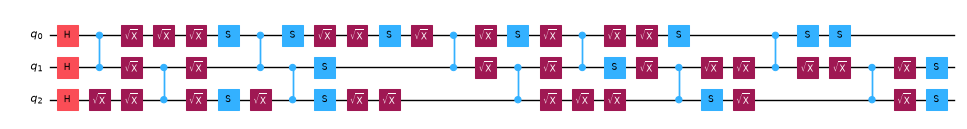

Representative best checked case: requested order=(0, 1), actual targets=(0, 1), checks=2, F=0.9875, kept=94.16%
Checked circuit drawing for this case (first sampled stabilizer, matching the game's circuit inspector)


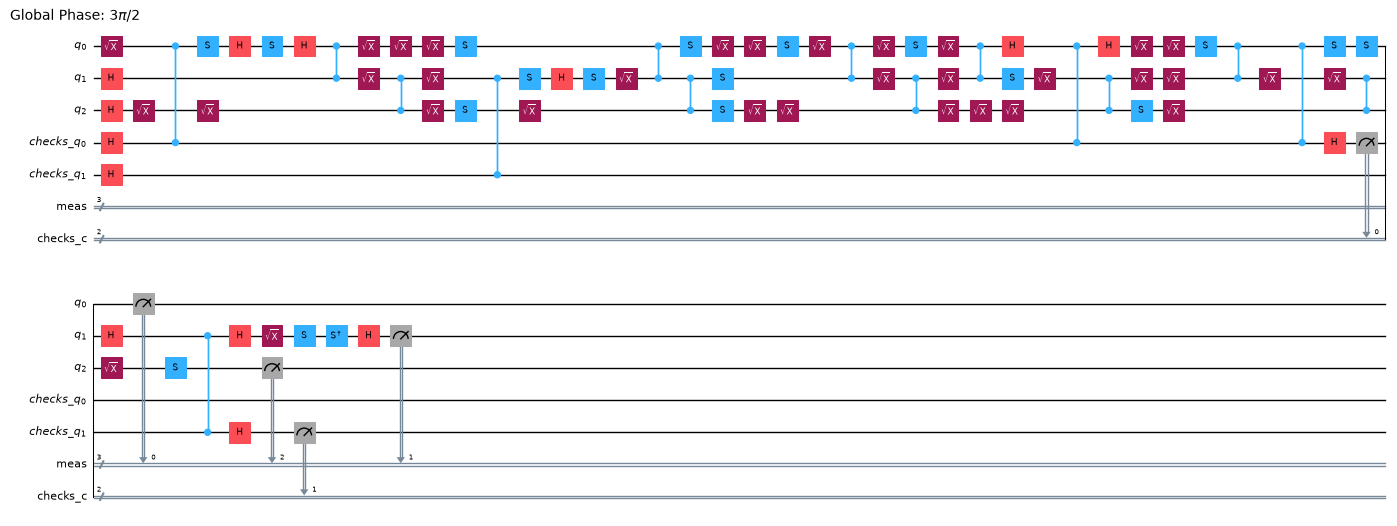

Fidelity vs kept shots


Pareto frontier: fidelity versus kept shots


Remaining exposure by qubit: no checks, game reference, and best checked case


,Qubit,Average undetected fault types (best checked)
0,q0,10.000
1,q1,11.714
2,q2,8.000


T-doping: exact post-selected fidelity and conservative bound; acceptance probability


T-doping: noisy fidelity and retained shots, checked versus unchecked


,T requested,T actually placed,Legal candidate sites,Check targets,No-check noisy fidelity,No-check kept shots (%),Checked post-selected fidelity,Checked kept shots (%),F1 Clifford fidelity,P(H|A) estimate,...,Unchecked 2Q gates,Checked 2Q gates,Added 2Q gates,Unchecked depth,Checked depth,Added ancillas,Trade-off winner,Best trade-off error,Bound holds,Checks preserved
0,0,0,2,"(0, 1)",0.97862,100.0,0.99299,97.33479,0.99299,0.00232,...,10,15,5,36,38,2,With checks,0.03907,True,True
1,1,1,2,"(0, 1)",0.97862,100.0,0.99315,97.33479,0.99299,0.00232,...,10,15,5,37,39,2,With checks,0.03891,True,True
2,2,2,2,"(0, 1)",0.97862,100.0,0.99331,97.33479,0.99299,0.00232,...,10,15,5,37,39,2,With checks,0.03874,True,True
3,4,2,2,"(0, 1)",0.97862,100.0,0.99331,97.33479,0.99299,0.00232,...,10,15,5,37,39,2,With checks,0.03874,True,True
4,8,2,2,"(0, 1)",0.97862,100.0,0.99331,97.33479,0.99299,0.00232,...,10,15,5,37,39,2,With checks,0.03874,True,True


In [7]:
# ======================= GAME-STYLE VISUALIZATIONS =======================
# This section reproduces the principal diagrams and plots shown in app.py.
# Plotly charts remain interactive in Jupyter; circuit drawings use Qiskit's Matplotlib drawer.
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from plotly.colors import qualitative

PLOT_PALETTE = qualitative.Plotly

# 1) Hardware layout and available ancilla/check sites (same concept as hardware_panel in app.py).
print("Hardware layout and available check sites")
n_data = session.level.width
hardware_fig = go.Figure()
hardware_fig.add_trace(go.Scatter(
    x=list(range(n_data)), y=[0] * n_data, mode="lines+markers+text",
    text=[f"q{q}<br>physical {p}" for q, p in enumerate(session.layout)],
    textposition="top center", marker=dict(size=22, color="#2a9d8f"),
    line=dict(color="#9aa0a6"), name="Data qubit"
))
ancilla_sites = [q for q in session.allowed if session.anc_phys.get(q) is not None]
for q in ancilla_sites:
    hardware_fig.add_trace(go.Scatter(
        x=[q, q], y=[0, -1], mode="lines",
        line=dict(color="#9aa0a6", dash="dot"), showlegend=False, hoverinfo="skip"
    ))
hardware_fig.add_trace(go.Scatter(
    x=ancilla_sites, y=[-1] * len(ancilla_sites), mode="markers+text",
    text=[f"ancilla {session.anc_phys[q]}" for q in ancilla_sites],
    textposition="bottom center", marker=dict(size=18, color="#f4a261"),
    name="Available check ancilla"
))
hardware_fig.update_layout(
    title=f"{session.backend.name}: physical layout and available check sites",
    height=300, margin=dict(t=55, b=20), yaxis=dict(visible=False), xaxis=dict(visible=False)
)
hardware_fig.show()
print(f"Backend={session.backend.name}; physical layout={session.layout}; check targets={session.allowed}; budget={session.budget}")

# 2) Original payload circuit drawing (as in the game's View the payload circuit expander).
print("Original Clifford payload circuit")
try:
    payload_fig = session.circ.draw("mpl", fold=40, scale=0.5, style="iqp")
except Exception:
    payload_fig = session.circ.draw("mpl", fold=40, scale=0.5)
display(payload_fig)
plt.close(payload_fig)

# 3) CZ workload by logical data qubit (supports the game's per-qubit payload-load diagnostic).
payload_load = session.payload_load()
payload_load_fig = go.Figure(go.Bar(
    x=[f"q{q}" for q in range(n_data)],
    y=[payload_load[q] for q in range(n_data)],
    text=[payload_load[q] for q in range(n_data)], textposition="outside", name="CZ gates"
))
payload_load_fig.update_layout(title="Payload CZ-gate load by logical qubit", yaxis_title="CZ gates touching qubit", height=330)
payload_load_fig.show()

# Pick the representative configuration corresponding to the best checked table row.
best_checked_record = results.iloc[0]
best_selection_index = int(best_checked_record["Selection index"])
best_check_count = int(best_checked_record["Checks inserted"])
best_viz = next(
    v for v in visualization_records
    if v["selection_index"] == best_selection_index and v["checks_inserted"] == best_check_count
)
print(f"Representative best checked case: requested order={best_viz['requested_order']}, "
      f"actual targets={best_viz['actual_targets']}, checks={best_check_count}, "
      f"F={best_viz['F']:.4f}, kept={100*best_viz['K']:.2f}%")
print("Checked circuit drawing for this case (first sampled stabilizer, matching the game's circuit inspector)")
try:
    checked_fig = best_viz["circuit"].draw("mpl", fold=40, scale=0.5, style="iqp")
except Exception:
    checked_fig = best_viz["circuit"].draw("mpl", fold=40, scale=0.5)
display(checked_fig)
plt.close(checked_fig)

# 4) Fidelity vs kept-shot fraction: one trace per requested target-order selection,
# with markers labelled by the number of checks (matching the in-game frontier).
print("Fidelity vs kept shots")
frontier_fig = go.Figure()
all_selection_scores = results.groupby("Selection index")["Trade-off error (lower is better)"].min().sort_values()
VIS_MAX_FRONTIER_LINES = 40  # edit for more/less detail; the Pareto plot below uses every configuration.
selected_orders = list(all_selection_scores.index[:VIS_MAX_FRONTIER_LINES])
for j, selection_idx in enumerate(selected_orders):
    group = results[results["Selection index"] == selection_idx].sort_values("Checks inserted")
    if group.empty:
        continue
    # Add the no-check starting point, like the marginal curve exposed by each game run.
    x = [float(session.baseline["K"])] + (group["Kept shots (%)"].to_numpy(dtype=float) / 100).tolist()
    y = [float(session.baseline["F"])] + group["Fidelity"].to_numpy(dtype=float).tolist()
    labels = ["0"] + group["Checks inserted"].astype(str).tolist()
    targets = group.iloc[0]["Requested target order"]
    frontier_fig.add_trace(go.Scatter(
        x=x, y=y, mode="lines+markers+text", text=labels, textposition="bottom center",
        name=f"Order {selection_idx}: {targets}", line=dict(color=PLOT_PALETTE[j % len(PLOT_PALETTE)]),
        customdata=[[0, float(session.baseline["error"])]] + [
            [int(r["Checks inserted"]), float(r["Trade-off error (lower is better)"])] for _, r in group.iterrows()
        ], hovertemplate="%{customdata[0]} check(s)<br>K=%{x:.3f}<br>F=%{y:.3f}<br>objective=%{customdata[1]:.4f}<extra></extra>"
    ))
# Clearly mark the game reference, if it is distinct from the no-check start.
frontier_fig.add_trace(go.Scatter(
    x=[float(session.par["K"])], y=[float(session.par["F"])], mode="markers",
    marker=dict(size=12, symbol="diamond", color="#7b2cbf", line=dict(width=1, color="white")),
    name="Game reference"
))
frontier_fig.update_layout(
    xaxis=dict(title="Kept-shot fraction (K; reversed like game view)", autorange="reversed"),
    yaxis_title="Post-selected fidelity", height=520, margin=dict(t=30),
    title="Fidelity versus kept shots across target-order selections"
)
frontier_fig.show()
if len(all_selection_scores) > len(selected_orders):
    print(f"For readability, the frontier plots the {len(selected_orders)} best selection orders. "
          "The tables and Pareto plot below still use every completed configuration.")

# 5) Pareto plot: all checked configurations, coloured by number of checks, plus a continuous Pareto line.
print("Pareto frontier: fidelity versus kept shots")
pareto_fig = go.Figure()
all_points = []
for k, group in results.groupby("Checks inserted"):
    pareto_fig.add_trace(go.Scatter(
        x=group["Kept shots (%)"] / 100, y=group["Fidelity"], mode="markers",
        name=f"{int(k)} check(s)", marker=dict(size=8, color=PLOT_PALETTE[(int(k)-1) % len(PLOT_PALETTE)]),
        customdata=[
            [str(r["Requested target order"]), float(r["Trade-off error (lower is better)"]),
             float(r["Mean 2Q gates across stabilizer circuits"]), int(r["Representative circuit depth"])]
            for _, r in group.iterrows()
        ], hovertemplate="targets=%{customdata[0]}<br>K=%{x:.3f}<br>F=%{y:.4f}<br>objective=%{customdata[1]:.4f}<br>2Q gates=%{customdata[2]}<br>depth=%{customdata[3]}<extra></extra>"
    ))
    all_points.extend(zip(group["Kept shots (%)"].to_numpy(dtype=float) / 100, group["Fidelity"].to_numpy(dtype=float)))
# Include the no-check and game reference points in the Pareto analysis.
all_points.extend([
    (float(session.baseline["K"]), float(session.baseline["F"])),
    (float(session.par["K"]), float(session.par["F"])),
])
unique_points = sorted(set((float(k), float(f)) for k, f in all_points if np.isfinite(k) and np.isfinite(f)), key=lambda p: (-p[0], -p[1]))
pareto_points = []
best_f = -float("inf")
for k, f in unique_points:
    if f > best_f:
        pareto_points.append((k, f))
        best_f = f
if pareto_points:
    pareto_fig.add_trace(go.Scatter(
        x=[p[0] for p in pareto_points], y=[p[1] for p in pareto_points], mode="lines+markers",
        name="Pareto frontier", line=dict(color="#e63946", width=3, shape="linear"), marker=dict(size=6)
    ))
pareto_fig.add_trace(go.Scatter(
    x=[session.baseline["K"]], y=[session.baseline["F"]], mode="markers", name="No-check baseline",
    marker=dict(size=12, symbol="star", color="#e9c46a", line=dict(width=1, color="#555555"))
))
pareto_fig.add_trace(go.Scatter(
    x=[session.par["K"]], y=[session.par["F"]], mode="markers", name="Game reference",
    marker=dict(size=11, symbol="diamond", color="#7b2cbf")
))
pareto_fig.update_layout(title="All configurations and Pareto frontier", xaxis_title="Kept-shot fraction (K)",
                         yaxis_title="Fidelity", height=500, margin=dict(t=35))
pareto_fig.show()

# 6) Coverage comparison by qubit, using the same undetected-fault summary shown in the game.
print("Remaining exposure by qubit: no checks, game reference, and best checked case")
exposure_columns_local = [f"Remaining exposure q{q}" for q in range(n_data)]
coverage_fig = go.Figure()
coverage_specs = [
    ("No checks", session.baseline["unc_by_qubit"]),
    ("Game reference", session.par["unc_by_qubit"]),
    ("Best checked", best_viz["unc_by_qubit"]),
]
seen_coverage = set()
for name, values in coverage_specs:
    key_values = tuple(round(float(values[q]), 10) for q in range(n_data))
    if (name, key_values) in seen_coverage:
        continue
    seen_coverage.add((name, key_values))
    coverage_fig.add_trace(go.Bar(x=[f"q{q}" for q in range(n_data)],
                                  y=[float(values[q]) for q in range(n_data)], name=name))
coverage_fig.update_layout(barmode="group", title="Undetected fault types by qubit",
                           yaxis_title="Average undetected fault types", height=390, margin=dict(t=35))
coverage_fig.show()

# 7) Undetected-fault heatmap over qubit and approximate position in the representative checked circuit.
bins = 30
fault_grid = np.zeros((n_data, bins))
for q, pos in best_viz["unc_cells"]:
    bin_index = min(bins - 1, int(pos) * bins // (best_viz["n_inst"] + 1))
    if 0 <= int(q) < n_data:
        fault_grid[int(q), bin_index] += 1
fault_heatmap = go.Figure(go.Heatmap(
    z=fault_grid, y=[f"q{q}" for q in range(n_data)], x=list(range(bins)), colorscale="Reds",
    colorbar=dict(title="Undetected")
))
fault_heatmap.update_layout(title="Remaining fault exposure across circuit position (best checked case)",
                            xaxis_title="Circuit position (early → late)", yaxis_title="Data qubit",
                            height=350, margin=dict(t=40))
fault_heatmap.show()

# Also print an exposure table for the selected configuration.
exposure_best_table = pd.DataFrame({
    "Qubit": [f"q{q}" for q in range(n_data)],
    "Average undetected fault types (best checked)": [float(best_viz["unc_by_qubit"][q]) for q in range(n_data)],
})
display(exposure_best_table.round(3))

# 8) T-gate graphs match the game's exact-F2/bound and acceptance plots, plus checked-vs-unchecked trends.
if RUN_T_DOPING_SWEEP and "t_results" in globals() and not t_results.empty:
    print("T-doping: exact post-selected fidelity and conservative bound; acceptance probability")
    t_plot = t_results.sort_values("T actually placed")
    t_fig_nb = make_subplots(rows=1, cols=2,
                             subplot_titles=("Exact post-selected F2 and conservative bound", "Acceptance probability"))
    t_fig_nb.add_trace(go.Scatter(x=t_plot["T actually placed"], y=t_plot["Checked post-selected fidelity"],
                                  mode="lines+markers", name="Exact F2"), row=1, col=1)
    t_fig_nb.add_trace(go.Scatter(x=t_plot["T actually placed"], y=t_plot["Conservative fidelity bound"],
                                  mode="lines+markers", line=dict(dash="dash"), name="F1 − upper95(P(H|A))"), row=1, col=1)
    t_fig_nb.add_trace(go.Scatter(x=t_plot["T actually placed"], y=t_plot["Acceptance after doping (%)"],
                                  mode="lines+markers", name="P(accept), doped"), row=1, col=2)
    t_fig_nb.add_trace(go.Scatter(x=t_plot["T actually placed"], y=t_plot["Acceptance before doping (%)"],
                                  mode="lines+markers", line=dict(dash="dot"), name="P(accept), Clifford"), row=1, col=2)
    t_fig_nb.update_xaxes(title_text="T gates actually placed", dtick=1)
    t_fig_nb.update_yaxes(title_text="Fidelity", row=1, col=1)
    t_fig_nb.update_yaxes(title_text="Accepted shots (%)", row=1, col=2)
    t_fig_nb.update_layout(height=420, margin=dict(t=45))
    t_fig_nb.show()

    print("T-doping: noisy fidelity and retained shots, checked versus unchecked")
    t_compare_fig = make_subplots(rows=1, cols=2,
                                  subplot_titles=("Noisy fidelity", "Kept-shot fraction"))
    t_compare_fig.add_trace(go.Scatter(x=t_plot["T actually placed"], y=t_plot["No-check noisy fidelity"],
                                       mode="lines+markers", name="Without checks"), row=1, col=1)
    t_compare_fig.add_trace(go.Scatter(x=t_plot["T actually placed"], y=t_plot["Checked post-selected fidelity"],
                                       mode="lines+markers", name="With checks"), row=1, col=1)
    t_compare_fig.add_trace(go.Scatter(x=t_plot["T actually placed"], y=t_plot["No-check kept shots (%)"],
                                       mode="lines+markers", name="Without checks", showlegend=False), row=1, col=2)
    t_compare_fig.add_trace(go.Scatter(x=t_plot["T actually placed"], y=t_plot["Checked kept shots (%)"],
                                       mode="lines+markers", name="With checks", showlegend=False), row=1, col=2)
    t_compare_fig.update_xaxes(title_text="T gates actually placed", dtick=1)
    t_compare_fig.update_yaxes(title_text="Fidelity", row=1, col=1)
    t_compare_fig.update_yaxes(title_text="Kept shots (%)", row=1, col=2)
    t_compare_fig.update_layout(height=420, margin=dict(t=45))
    t_compare_fig.show()
    display(t_plot.round(5))
else:
    print("T-gate graphs skipped because RUN_T_DOPING_SWEEP=False. Enable it in the configuration cell to produce the game's T plots and checked-vs-unchecked comparison.")


In [8]:
# ======================= EXPORT TABLES =======================
if SAVE_CSV:
    output_path = Path(OUTPUT_DIR)
    output_path.mkdir(parents=True, exist_ok=True)
    stem = f"level_{LEVEL_NUMBER}_seed_{SEED}"
    metadata.to_csv(output_path / f"{stem}_metadata.csv", index=False)
    reference_table[reference_visible].to_csv(output_path / f"{stem}_reference.csv", index=False)
    all_comparison[all_visible_columns].to_csv(output_path / f"{stem}_overall_comparison.csv", index=False)
    results[visible_columns].to_csv(output_path / f"{stem}_all_check_configurations.csv", index=False)
    by_checks.to_csv(output_path / f"{stem}_summary_by_check_count.csv", index=False)
    by_depth.to_csv(output_path / f"{stem}_summary_by_depth.csv", index=False)
    by_placement.to_csv(output_path / f"{stem}_summary_by_placement.csv", index=False)
    exposure_table.to_csv(output_path / f"{stem}_best_configuration_exposure.csv", index=False)
    if RUN_T_DOPING_SWEEP:
        t_results.to_csv(output_path / f"{stem}_t_doping_sweep.csv", index=False)
    print(f"Saved analysis CSV files to: {output_path.resolve()}")

print("Reproducibility note: results depend on the installed Qiskit/Qiskit Aer/Qiskit Paulice versions and on which fake backend classes are available in that environment. Record the package versions alongside published results.")


Reproducibility note: results depend on the installed Qiskit/Qiskit Aer/Qiskit Paulice versions and on which fake backend classes are available in that environment. Record the package versions alongside published results.
